In [1]:
# =============================================================================
# CELL 1 : IMPORTS, GLOBAL CONFIGURATION AND REPRODUCIBILITY
# =============================================================================
# Lab 4 - Multiclass Logistic Regression (softmax) and Support Vector Machines
# Course : Pattern Recognition and Machine Learning (EE602L)
# Roll No: IS24BM008
# -----------------------------------------------------------------------------
# Everything in Question 1 (split, standardisation, one-hot encoding, softmax,
# cost, gradient, batch gradient descent and every evaluation metric) is written
# from scratch with NumPy only. scikit-learn is used ONLY to load the datasets
# and to provide the reference/library implementations we are asked to compare
# against (LogisticRegression in Q1c, SVC in the whole of Q2).
# =============================================================================

import os                                    # used only to create the figure folder
import numpy as np                           # all numerical work
import pandas as pd                          # tabular inspection of the datasets
import matplotlib.pyplot as plt              # all plots

# --- datasets ---------------------------------------------------------------
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.datasets import make_blobs, make_classification

# --- library models used for comparison / for Question 2 --------------------
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, roc_curve

# --- global reproducibility settings ----------------------------------------
RANDOM_SEED = 42                             # fixed seed demanded by the problem sheet
np.random.seed(RANDOM_SEED)                  # seeds the legacy global NumPy RNG

# --- folder where every figure of this notebook is written -------------------
FIGDIR = "figs"
os.makedirs(FIGDIR, exist_ok=True)

# --- matplotlib defaults so that every figure is readable in the report ------
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 160
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.30

# --- printing defaults -------------------------------------------------------
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

print("Libraries imported.")
print("NumPy", np.__version__, "| pandas", pd.__version__)
print("Global random seed :", RANDOM_SEED)


Libraries imported.
NumPy 2.4.1 | pandas 2.3.3
Global random seed : 42


In [2]:
# =============================================================================
# CELL 2 : FROM-SCRATCH UTILITIES - STRATIFIED SPLIT, STANDARDISATION, ONE-HOT
# =============================================================================
# These three helpers are used by both Question 1 and Question 2(c). They use
# NumPy only, so the "implement the split from scratch" requirement is met.
# =============================================================================

def stratified_split(y, ratios=(0.70, 0.15, 0.15), seed=RANDOM_SEED):
    """
    Split indices into train/validation/test with STRATIFIED sampling, i.e. the
    class proportions of the original data are preserved inside every subset.

    Parameters
    ----------
    y      : (m,) integer array of class labels.
    ratios : 3-tuple (train, val, test) that must sum to 1.
    seed   : integer seed, guarantees the split is reproducible.

    Returns
    -------
    idx_train, idx_val, idx_test : three arrays of integer positions into y.
    """
    assert abs(sum(ratios) - 1.0) < 1e-12, "the three ratios must sum to 1"

    rng = np.random.default_rng(seed)          # local generator -> reproducible
    idx_train, idx_val, idx_test = [], [], []

    # The split is done class by class; this is exactly what "stratified" means.
    for c in np.unique(y):
        idx_c = np.flatnonzero(y == c)         # positions of every sample of class c
        idx_c = rng.permutation(idx_c)         # shuffle them (seeded)

        n_c = idx_c.size
        n_train = int(round(ratios[0] * n_c))  # rounding keeps the ratio as close
        n_val = int(round(ratios[1] * n_c))    # to 70:15:15 as an integer allows
        n_test = n_c - n_train - n_val         # remainder -> no sample is lost

        idx_train.append(idx_c[:n_train])
        idx_val.append(idx_c[n_train:n_train + n_val])
        idx_test.append(idx_c[n_train + n_val:n_train + n_val + n_test])

    # Concatenate the per-class blocks and reshuffle so the subsets are not
    # ordered by class (important for any method sensitive to sample order).
    idx_train = rng.permutation(np.concatenate(idx_train))
    idx_val = rng.permutation(np.concatenate(idx_val))
    idx_test = rng.permutation(np.concatenate(idx_test))
    return idx_train, idx_val, idx_test


def standardize(X_train, *others):
    """
    Z-score standardisation  x -> (x - mu) / sigma  where mu and sigma are
    computed on the TRAINING SET ONLY (no information from val/test leaks in).

    Returns the standardised training matrix, then the standardised versions of
    every additional matrix passed in, then the (mu, sigma) pair itself.
    """
    mu = X_train.mean(axis=0)                  # per-feature training mean
    sigma = X_train.std(axis=0)                # per-feature training std (ddof = 0)
    sigma[sigma == 0.0] = 1.0                  # guard against constant features

    out = [(X_train - mu) / sigma]
    for X in others:
        out.append((X - mu) / sigma)           # SAME mu / sigma reused everywhere
    out.append((mu, sigma))
    return tuple(out)


def one_hot(y, n_classes):
    """
    Convert integer labels (m,) into a one-hot matrix (m, n_classes).
    Row i is a vector of zeros with a single 1 in column y[i].
    """
    Y = np.zeros((y.size, n_classes))
    Y[np.arange(y.size), y] = 1.0
    return Y


def add_bias(X):
    """Prepend a column of ones so the intercept is learned like any weight."""
    return np.hstack([np.ones((X.shape[0], 1)), X])


print("Utility functions defined : stratified_split, standardize, one_hot, add_bias")


Utility functions defined : stratified_split, standardize, one_hot, add_bias


WINE DATASET - SHAPE AND CLASS BALANCE
Feature matrix shape : (178, 13)
Label vector shape   : (178,)
Classes              : ['class_0', 'class_1', 'class_2']

 class_index class_name  count  proportion
           0    class_0     59      0.3315
           1    class_1     71      0.3989
           2    class_2     48      0.2697

SUMMARY STATISTICS OF THE 13 RAW FEATURES
                                 mean      std     min   median      max
alcohol                        13.001    0.812   11.03   13.050    14.83
malic_acid                      2.336    1.117    0.74    1.865     5.80
ash                             2.367    0.274    1.36    2.360     3.23
alcalinity_of_ash              19.495    3.340   10.60   19.500    30.00
magnesium                      99.742   14.282   70.00   98.000   162.00
total_phenols                   2.295    0.626    0.98    2.355     3.88
flavanoids                      2.029    0.999    0.34    2.135     5.08
nonflavanoid_phenols            0.362    

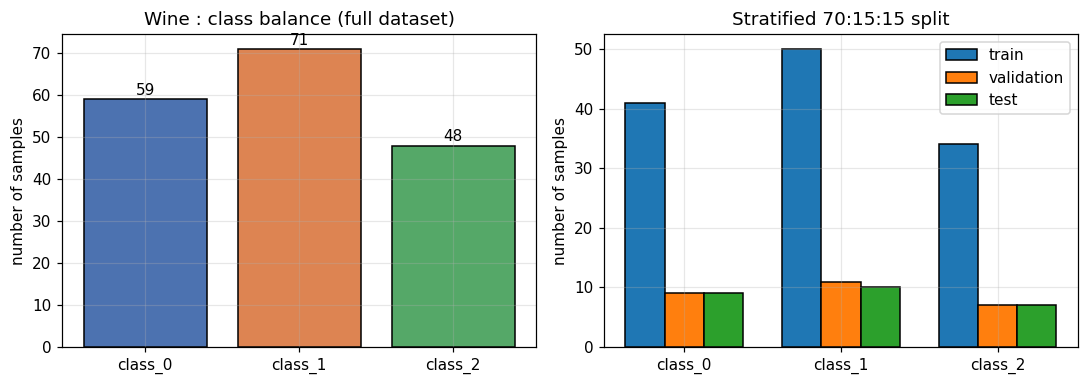

In [3]:
# =============================================================================
# CELL 3 : Q1(a) - LOAD THE WINE DATASET, INSPECT IT, SPLIT, SCALE, ENCODE
# =============================================================================

# --- load --------------------------------------------------------------------
wine = load_wine()
X_wine = wine.data                              # (178, 13) numerical features
y_wine = wine.target                            # (178,)   integer labels 0/1/2
feature_names = list(wine.feature_names)
class_names = [str(c) for c in wine.target_names]   # plain Python strings
K_WINE = len(class_names)                       # number of classes = 3

print("=" * 78)
print("WINE DATASET - SHAPE AND CLASS BALANCE")
print("=" * 78)
print("Feature matrix shape :", X_wine.shape)
print("Label vector shape   :", y_wine.shape)
print("Classes              :", class_names)

# --- class balance -----------------------------------------------------------
counts = np.bincount(y_wine)
balance = pd.DataFrame({
    "class_index": np.arange(K_WINE),
    "class_name": class_names,
    "count": counts,
    "proportion": np.round(counts / counts.sum(), 4),
})
print()
print(balance.to_string(index=False))

# --- summary statistics of the 13 raw features -------------------------------
df_wine = pd.DataFrame(X_wine, columns=feature_names)
summary = df_wine.describe().T[["mean", "std", "min", "50%", "max"]]
summary.columns = ["mean", "std", "min", "median", "max"]
print()
print("=" * 78)
print("SUMMARY STATISTICS OF THE 13 RAW FEATURES")
print("=" * 78)
print(summary.round(3).to_string())
print()
print("Missing values in the whole dataset :", int(df_wine.isna().sum().sum()))
print("NOTE the very different feature ranges (e.g. proline ~ 10^3 against")
print("     nonflavanoid_phenols ~ 10^-1); this is why standardisation matters.")

# --- 70:15:15 stratified split, seed 42 --------------------------------------
tr, va, te = stratified_split(y_wine, (0.70, 0.15, 0.15), seed=RANDOM_SEED)
Xtr_raw, ytr = X_wine[tr], y_wine[tr]
Xva_raw, yva = X_wine[va], y_wine[va]
Xte_raw, yte = X_wine[te], y_wine[te]

print()
print("=" * 78)
print("70:15:15 STRATIFIED SPLIT (seed = 42)")
print("=" * 78)
split_tbl = pd.DataFrame({
    "subset": ["train", "validation", "test"],
    "n_samples": [ytr.size, yva.size, yte.size],
    "class_0": [int((ytr == 0).sum()), int((yva == 0).sum()), int((yte == 0).sum())],
    "class_1": [int((ytr == 1).sum()), int((yva == 1).sum()), int((yte == 1).sum())],
    "class_2": [int((ytr == 2).sum()), int((yva == 2).sum()), int((yte == 2).sum())],
})
split_tbl["fraction"] = np.round(split_tbl["n_samples"] / y_wine.size, 4)
print(split_tbl.to_string(index=False))

# sanity check : the three index sets must be disjoint and cover everything
assert len(set(tr) | set(va) | set(te)) == y_wine.size, "split does not cover the data"
assert len(set(tr) & set(va)) == 0 and len(set(tr) & set(te)) == 0, "overlap found"
assert len(set(va) & set(te)) == 0, "overlap found"
print("\nDisjointness / coverage assertions passed.")

# --- standardise using TRAINING statistics only -------------------------------
Xtr, Xva, Xte, (mu_w, sd_w) = standardize(Xtr_raw, Xva_raw, Xte_raw)
print("Training mean after scaling (should be ~0) :", np.round(Xtr.mean(axis=0), 6)[:5], "...")
print("Training std  after scaling (should be ~1) :", np.round(Xtr.std(axis=0), 6)[:5], "...")
print("Validation mean after scaling (NOT exactly 0, as expected) :",
      np.round(Xva.mean(axis=0), 4)[:5], "...")

# --- one-hot encode the targets used for training -----------------------------
Ytr = one_hot(ytr, K_WINE)
Yva = one_hot(yva, K_WINE)
Yte = one_hot(yte, K_WINE)
print("\nOne-hot training target shape :", Ytr.shape)
print("First 5 integer labels        :", ytr[:5])
print("First 5 one-hot rows          :\n", Ytr[:5].astype(int))

# --- design matrices with the bias column -------------------------------------
Xtr_b, Xva_b, Xte_b = add_bias(Xtr), add_bias(Xva), add_bias(Xte)
print("\nDesign matrix with bias column :", Xtr_b.shape)

# --- figure : class balance ----------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(class_names, counts, color=["#4C72B0", "#DD8452", "#55A868"], edgecolor="k")
for i, c in enumerate(counts):
    ax[0].text(i, c + 1, str(c), ha="center")
ax[0].set_title("Wine : class balance (full dataset)")
ax[0].set_ylabel("number of samples")

width = 0.25
xpos = np.arange(K_WINE)
ax[1].bar(xpos - width, split_tbl.loc[0, ["class_0", "class_1", "class_2"]].values,
          width, label="train", edgecolor="k")
ax[1].bar(xpos, split_tbl.loc[1, ["class_0", "class_1", "class_2"]].values,
          width, label="validation", edgecolor="k")
ax[1].bar(xpos + width, split_tbl.loc[2, ["class_0", "class_1", "class_2"]].values,
          width, label="test", edgecolor="k")
ax[1].set_xticks(xpos)
ax[1].set_xticklabels(class_names)
ax[1].set_title("Stratified 70:15:15 split")
ax[1].set_ylabel("number of samples")
ax[1].legend()
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q1a_class_balance.png", bbox_inches="tight")
plt.show()


In [4]:
# =============================================================================
# CELL 4 : Q1(b) - SOFTMAX, CROSS-ENTROPY COST, GRADIENT, GRADIENT CHECK
# =============================================================================
# Model :  z = X theta            with theta of shape (n+1, K)
#          P(y = k | x) = exp(z_k) / sum_j exp(z_j)          (softmax)
# Cost  :  J(theta) = -(1/m) sum_i sum_k  Y_ik * log P_ik    (cross-entropy)
# Grad  :  dJ/dtheta = (1/m) X^T (P - Y)
# =============================================================================

def softmax(Z):
    """
    Numerically stable softmax applied row-wise.

    Subtracting the row maximum before exponentiating does not change the result
    (the constant cancels between numerator and denominator) but it prevents
    exp() from overflowing when the scores are large.
    """
    Z_shift = Z - Z.max(axis=1, keepdims=True)
    expZ = np.exp(Z_shift)
    return expZ / expZ.sum(axis=1, keepdims=True)


def cross_entropy_cost(X, Y, theta):
    """
    Average multiclass cross-entropy.

    Computed in the log-sum-exp form
        J = (1/m) sum_i [ logsumexp_k(z_ik) - z_i,y_i ]
    which is algebraically identical to -(1/m) sum Y*log(softmax(z)) but never
    evaluates log() of a number that has underflowed to zero.
    """
    Z = X @ theta
    Z_shift = Z - Z.max(axis=1, keepdims=True)
    log_sum_exp = Z.max(axis=1) + np.log(np.exp(Z_shift).sum(axis=1))
    correct_class_score = np.sum(Y * Z, axis=1)          # z_i,y_i via the one-hot mask
    return float(np.mean(log_sum_exp - correct_class_score))


def cross_entropy_gradient(X, Y, theta):
    """Analytic gradient of the cost above : (1/m) X^T (P - Y), shape (n+1, K)."""
    m = X.shape[0]
    P = softmax(X @ theta)
    return (X.T @ (P - Y)) / m


# --- numerical verification of the analytic gradient --------------------------
# Central finite differences on a small random problem. If the analytic gradient
# is correct the relative error is at machine-precision level (~1e-9 or less).
rng_check = np.random.default_rng(0)
X_chk = rng_check.normal(size=(15, 5))
y_chk = rng_check.integers(0, 3, size=15)
Y_chk = one_hot(y_chk, 3)
th_chk = rng_check.normal(scale=0.5, size=(5, 3))

grad_analytic = cross_entropy_gradient(X_chk, Y_chk, th_chk)
grad_numeric = np.zeros_like(th_chk)
eps = 1e-6
for i in range(th_chk.shape[0]):
    for j in range(th_chk.shape[1]):
        th_plus = th_chk.copy()
        th_minus = th_chk.copy()
        th_plus[i, j] += eps
        th_minus[i, j] -= eps
        grad_numeric[i, j] = (cross_entropy_cost(X_chk, Y_chk, th_plus)
                              - cross_entropy_cost(X_chk, Y_chk, th_minus)) / (2 * eps)

rel_err = (np.linalg.norm(grad_analytic - grad_numeric)
           / (np.linalg.norm(grad_analytic) + np.linalg.norm(grad_numeric)))
print("=" * 78)
print("GRADIENT CHECK (central finite differences, eps = 1e-6)")
print("=" * 78)
print("relative error between analytic and numerical gradient : {:.3e}".format(rel_err))
print("max absolute difference                                : {:.3e}"
      .format(np.abs(grad_analytic - grad_numeric).max()))
assert rel_err < 1e-7, "analytic gradient is wrong"
print("Gradient check PASSED.")


GRADIENT CHECK (central finite differences, eps = 1e-6)
relative error between analytic and numerical gradient : 5.526e-10
max absolute difference                                : 2.404e-10
Gradient check PASSED.


BATCH GRADIENT DESCENT - LEARNING RATE SWEEP (3000 iterations each)
lr = 0.005  | final train CE = 0.078832 | final val CE = 0.076045 | train acc = 0.9920 | val acc = 1.0000
lr = 0.05   | final train CE = 0.016519 | final val CE = 0.051590 | train acc = 1.0000 | val acc = 0.9630
lr = 0.5    | final train CE = 0.002421 | final val CE = 0.069817 | train acc = 1.0000 | val acc = 0.9630
lr = 1.5    | final train CE = 0.000871 | final val CE = 0.086955 | train acc = 1.0000 | val acc = 0.9630

Selected learning rate (lowest validation cross-entropy) : 0.05
   validation CE = 0.051590
   validation accuracy = 0.9630

 learning_rate  final_train_CE  final_val_CE  train_accuracy  val_accuracy
         0.005        0.078832      0.076045           0.992      1.000000
         0.050        0.016519      0.051590           1.000      0.962963
         0.500        0.002421      0.069817           1.000      0.962963
         1.500        0.000871      0.086955           1.000      0.962963


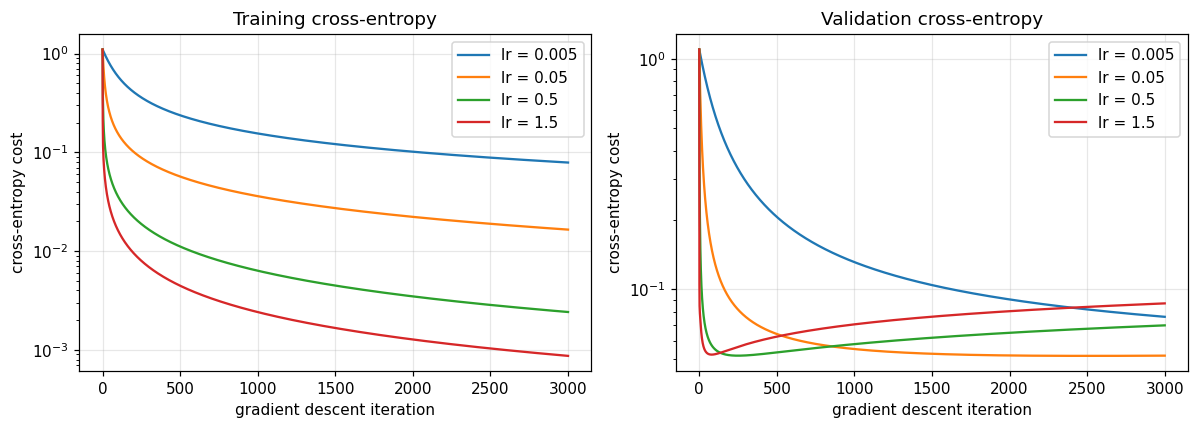

In [5]:
# =============================================================================
# CELL 5 : Q1(b) - BATCH GRADIENT DESCENT AND LEARNING-RATE SELECTION
# =============================================================================

def train_softmax_gd(X, Y, lr, n_iter, X_val=None, Y_val=None, verbose_every=0):
    """
    Full-batch gradient descent for softmax regression.

    Every iteration uses the WHOLE training set to compute one gradient
    (that is what "batch" gradient descent means) and applies
        theta <- theta - lr * gradient.

    Returns theta and the train/validation cost recorded at every iteration.
    """
    n_features, n_classes = X.shape[1], Y.shape[1]
    theta = np.zeros((n_features, n_classes))     # zero initialisation: the cost
                                                  # is convex, so this is safe
    hist_train, hist_val = [], []
    for it in range(n_iter):
        hist_train.append(cross_entropy_cost(X, Y, theta))
        if X_val is not None:
            hist_val.append(cross_entropy_cost(X_val, Y_val, theta))
        theta -= lr * cross_entropy_gradient(X, Y, theta)
        if verbose_every and (it + 1) % verbose_every == 0:
            print("    iter {:5d} | train CE = {:.6f}".format(it + 1, hist_train[-1]))
    # cost of the final parameters (after the last update)
    hist_train.append(cross_entropy_cost(X, Y, theta))
    if X_val is not None:
        hist_val.append(cross_entropy_cost(X_val, Y_val, theta))
    return theta, np.array(hist_train), np.array(hist_val)


def accuracy(y_true, y_pred):
    """Fraction of correctly classified samples."""
    return float(np.mean(y_true == y_pred))


def predict_classes(X, theta):
    """Predicted label = argmax_k P(y = k | x); argmax of z is the same as of P."""
    return np.argmax(X @ theta, axis=1)


# --- train with four learning rates -------------------------------------------
LEARNING_RATES = [0.005, 0.05, 0.5, 1.5]        # four rates, two orders of magnitude
N_ITER = 3000                                   # iterations of batch gradient descent

results_lr = {}
print("=" * 78)
print("BATCH GRADIENT DESCENT - LEARNING RATE SWEEP ({} iterations each)".format(N_ITER))
print("=" * 78)
for lr in LEARNING_RATES:
    theta_lr, h_tr, h_va = train_softmax_gd(Xtr_b, Ytr, lr, N_ITER, Xva_b, Yva)
    results_lr[lr] = {
        "theta": theta_lr,
        "hist_train": h_tr,
        "hist_val": h_va,
        "train_ce": h_tr[-1],
        "val_ce": h_va[-1],
        "train_acc": accuracy(ytr, predict_classes(Xtr_b, theta_lr)),
        "val_acc": accuracy(yva, predict_classes(Xva_b, theta_lr)),
    }
    print("lr = {:<6} | final train CE = {:.6f} | final val CE = {:.6f} | "
          "train acc = {:.4f} | val acc = {:.4f}"
          .format(lr, h_tr[-1], h_va[-1],
                  results_lr[lr]["train_acc"], results_lr[lr]["val_acc"]))

# --- model selection : lowest VALIDATION cross-entropy ------------------------
best_lr = min(LEARNING_RATES, key=lambda a: results_lr[a]["val_ce"])
theta_best = results_lr[best_lr]["theta"]
print()
print("Selected learning rate (lowest validation cross-entropy) : {}".format(best_lr))
print("   validation CE = {:.6f}".format(results_lr[best_lr]["val_ce"]))
print("   validation accuracy = {:.4f}".format(results_lr[best_lr]["val_acc"]))

# --- table of the sweep --------------------------------------------------------
lr_table = pd.DataFrame({
    "learning_rate": LEARNING_RATES,
    "final_train_CE": [results_lr[a]["train_ce"] for a in LEARNING_RATES],
    "final_val_CE": [results_lr[a]["val_ce"] for a in LEARNING_RATES],
    "train_accuracy": [results_lr[a]["train_acc"] for a in LEARNING_RATES],
    "val_accuracy": [results_lr[a]["val_acc"] for a in LEARNING_RATES],
})
print()
print(lr_table.round(6).to_string(index=False))

# --- figure : convergence curves ------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lr in LEARNING_RATES:
    ax[0].plot(results_lr[lr]["hist_train"], label="lr = {}".format(lr))
    ax[1].plot(results_lr[lr]["hist_val"], label="lr = {}".format(lr))
ax[0].set_title("Training cross-entropy")
ax[1].set_title("Validation cross-entropy")
for a in ax:
    a.set_xlabel("gradient descent iteration")
    a.set_ylabel("cross-entropy cost")
    a.set_yscale("log")
    a.legend()
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q1b_learning_curves.png", bbox_inches="tight")
plt.show()


In [6]:
# =============================================================================
# CELL 6 : Q1(b) - NUMERICAL PROOF THAT SOFTMAX WITH K = 2 IS THE SIGMOID
# =============================================================================
# Part 1 : the algebraic identity, checked on random scores.
#          softmax(z)_1 = e^{z1} / (e^{z0} + e^{z1})
#                       = 1 / (1 + e^{-(z1 - z0)}) = sigmoid(z1 - z0)
#          The softmax is over-parameterised: only the DIFFERENCE of the two
#          score vectors matters, which is why we may fix theta_0 = 0 (gauge).
#
# Part 2 : the identity at the level of the trained model. On a 2-class subset
#          of Wine we run (i) softmax GD with the first column of theta frozen
#          at zero and (ii) ordinary binary logistic regression with the sigmoid.
#          Same learning rate, same iterations, same initialisation -> the two
#          parameter vectors must agree to machine precision.
# =============================================================================

def sigmoid(z):
    """Numerically stable logistic sigmoid, evaluated branch-wise."""
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    exp_z = np.exp(z[~pos])
    out[~pos] = exp_z / (1.0 + exp_z)
    return out


print("=" * 78)
print("PART 1 : ALGEBRAIC IDENTITY ON RANDOM SCORES")
print("=" * 78)
rng_id = np.random.default_rng(7)
Z_rand = rng_id.normal(scale=6.0, size=(2000, 2))       # wide range on purpose
p_softmax = softmax(Z_rand)[:, 1]                       # P(class 1) from softmax
p_sigmoid = sigmoid(Z_rand[:, 1] - Z_rand[:, 0])        # P(class 1) from sigmoid
print("max |softmax(z)_1 - sigmoid(z1 - z0)| over 2000 random score pairs : {:.3e}"
      .format(np.abs(p_softmax - p_sigmoid).max()))

print()
print("=" * 78)
print("PART 2 : TRAINED MODELS AGREE ON A 2-CLASS SUBSET OF WINE")
print("=" * 78)

# --- build the 2-class subset (classes 0 and 1 of Wine) -----------------------
mask2 = y_wine < 2
X2_raw, y2 = X_wine[mask2], y_wine[mask2]
tr2, va2, te2 = stratified_split(y2, (0.70, 0.15, 0.15), seed=RANDOM_SEED)
X2tr_raw, y2tr = X2_raw[tr2], y2[tr2]
X2tr, (mu2, sd2) = standardize(X2tr_raw)
X2tr_b = add_bias(X2tr)
Y2tr = one_hot(y2tr, 2)
print("2-class subset : {} samples, {} in the training part"
      .format(y2.size, y2tr.size))

LR_EQ, IT_EQ = 0.5, 800                       # identical settings for both models

# --- (i) softmax with theta_0 frozen at zero (this IS "fixing theta_2 = 0") ---
theta_sm = np.zeros((X2tr_b.shape[1], 2))
for _ in range(IT_EQ):
    g = cross_entropy_gradient(X2tr_b, Y2tr, theta_sm)
    g[:, 0] = 0.0                             # freeze the reference class column
    theta_sm -= LR_EQ * g

# --- (ii) plain binary logistic regression driven by the sigmoid --------------
w_bin = np.zeros(X2tr_b.shape[1])
for _ in range(IT_EQ):
    p = sigmoid(X2tr_b @ w_bin)
    grad_bin = X2tr_b.T @ (p - y2tr) / y2tr.size
    w_bin -= LR_EQ * grad_bin

# --- compare the two parameter vectors and the two probability vectors --------
diff_theta = np.abs(theta_sm[:, 1] - w_bin).max()
p_from_softmax = softmax(X2tr_b @ theta_sm)[:, 1]
p_from_sigmoid = sigmoid(X2tr_b @ w_bin)
diff_prob = np.abs(p_from_softmax - p_from_sigmoid).max()

print("frozen column theta_0 (must be all zeros)      :", theta_sm[:, 0])
print("max |theta_1 - w_binary|                       : {:.3e}".format(diff_theta))
print("max |P_softmax(y=1|x) - sigmoid(x.w)|          : {:.3e}".format(diff_prob))
print()
print("first 5 parameters, softmax column 1 :", np.round(theta_sm[:5, 1], 8))
print("first 5 parameters, binary sigmoid   :", np.round(w_bin[:5], 8))
assert diff_theta < 1e-10 and diff_prob < 1e-10, "the K = 2 reduction failed"
print()
print("VERIFIED : with K = 2 and theta_0 fixed to 0, softmax regression is")
print("           exactly binary logistic regression with the sigmoid.")

VERIF_MAX_IDENTITY = float(np.abs(p_softmax - p_sigmoid).max())
VERIF_MAX_THETA = float(diff_theta)
VERIF_MAX_PROB = float(diff_prob)


PART 1 : ALGEBRAIC IDENTITY ON RANDOM SCORES
max |softmax(z)_1 - sigmoid(z1 - z0)| over 2000 random score pairs : 0.000e+00

PART 2 : TRAINED MODELS AGREE ON A 2-CLASS SUBSET OF WINE
2-class subset : 130 samples, 91 in the training part
frozen column theta_0 (must be all zeros)      : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
max |theta_1 - w_binary|                       : 4.441e-16
max |P_softmax(y=1|x) - sigmoid(x.w)|          : 5.551e-17

first 5 parameters, softmax column 1 : [-0.1158 -2.7856 -1.0784 -1.9633  2.5357]
first 5 parameters, binary sigmoid   : [-0.1158 -2.7856 -1.0784 -1.9633  2.5357]

VERIFIED : with K = 2 and theta_0 fixed to 0, softmax regression is
           exactly binary logistic regression with the sigmoid.


FROM-SCRATCH SOFTMAX REGRESSION - TEST SET RESULTS (lr = 0.05)
Confusion matrix (rows = true class, columns = predicted class)
              pred_class_0  pred_class_1  pred_class_2
true_class_0             9             0             0
true_class_1             0            10             0
true_class_2             0             0             7

  class  support  precision  recall  f1
class_0        9        1.0     1.0 1.0
class_1       10        1.0     1.0 1.0
class_2        7        1.0     1.0 1.0

accuracy          : 1.0000
macro precision   : 1.0000
macro recall      : 1.0000
macro F1          : 1.0000
multiclass log-loss (computed manually) : 0.007035


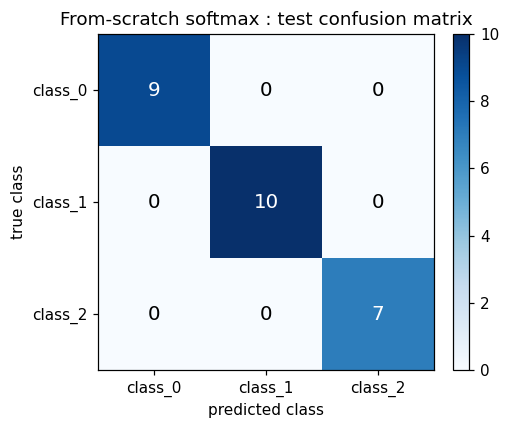

In [7]:
# =============================================================================
# CELL 7 : Q1(c) - EVALUATION METRICS WRITTEN FROM SCRATCH
# =============================================================================

def confusion_matrix_scratch(y_true, y_pred, n_classes):
    """
    Confusion matrix C with C[i, j] = number of samples whose true class is i
    and whose predicted class is j. Rows are truth, columns are predictions.
    """
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def prf_from_confusion(cm):
    """
    Per-class precision, recall and F1 derived from the confusion matrix.

        TP_k = C[k, k]
        FP_k = (column k sum) - TP_k      predicted k but truly something else
        FN_k = (row    k sum) - TP_k      truly k but predicted something else

        precision_k = TP / (TP + FP)      recall_k = TP / (TP + FN)
        F1_k        = 2 * P * R / (P + R)

    Divisions with a zero denominator are defined to be 0, the usual convention.
    """
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp

    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    return precision, recall, f1


def macro_average(values):
    """Macro average = unweighted mean over classes (every class counts equally)."""
    return float(np.mean(values))


def log_loss_scratch(y_true, P):
    """
    Multiclass log-loss  L = -(1/m) sum_i log P[i, y_i].
    Probabilities are clipped away from 0 and 1 so log() stays finite, and each
    row is renormalised after clipping so it still sums to one.
    """
    eps = 1e-15
    P_clipped = np.clip(P, eps, 1 - eps)
    P_clipped = P_clipped / P_clipped.sum(axis=1, keepdims=True)
    return float(-np.mean(np.log(P_clipped[np.arange(y_true.size), y_true])))


# --- apply the metrics to the selected from-scratch model on the TEST set ------
P_test_scratch = softmax(Xte_b @ theta_best)          # predicted probabilities
yhat_scratch = np.argmax(P_test_scratch, axis=1)      # argmax_k P(y = k | x)

cm_scratch = confusion_matrix_scratch(yte, yhat_scratch, K_WINE)
prec_s, rec_s, f1_s = prf_from_confusion(cm_scratch)
acc_scratch = accuracy(yte, yhat_scratch)
ll_scratch = log_loss_scratch(yte, P_test_scratch)

print("=" * 78)
print("FROM-SCRATCH SOFTMAX REGRESSION - TEST SET RESULTS (lr = {})".format(best_lr))
print("=" * 78)
print("Confusion matrix (rows = true class, columns = predicted class)")
print(pd.DataFrame(cm_scratch,
                   index=["true_" + c for c in class_names],
                   columns=["pred_" + c for c in class_names]).to_string())
print()
per_class = pd.DataFrame({
    "class": class_names,
    "support": cm_scratch.sum(axis=1),
    "precision": prec_s,
    "recall": rec_s,
    "f1": f1_s,
})
print(per_class.round(4).to_string(index=False))
print()
print("accuracy          : {:.4f}".format(acc_scratch))
print("macro precision   : {:.4f}".format(macro_average(prec_s)))
print("macro recall      : {:.4f}".format(macro_average(rec_s)))
print("macro F1          : {:.4f}".format(macro_average(f1_s)))
print("multiclass log-loss (computed manually) : {:.6f}".format(ll_scratch))

# --- figure : confusion matrix -------------------------------------------------
fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.imshow(cm_scratch, cmap="Blues")
ax.set_xticks(range(K_WINE))
ax.set_yticks(range(K_WINE))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("From-scratch softmax : test confusion matrix")
for i in range(K_WINE):
    for j in range(K_WINE):
        ax.text(j, i, cm_scratch[i, j], ha="center", va="center",
                color="white" if cm_scratch[i, j] > cm_scratch.max() / 2 else "black",
                fontsize=13)
ax.grid(False)
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q1c_confusion_scratch.png", bbox_inches="tight")
plt.show()


sklearn LogisticRegression - TEST SET RESULTS
Solver : lbfgs | penalty : deprecated | C : 1.0 | iterations used : [17]

Confusion matrix
              pred_class_0  pred_class_1  pred_class_2
true_class_0             9             0             0
true_class_1             0            10             0
true_class_2             0             0             7

accuracy        : 1.0000
macro precision : 1.0000
macro recall    : 1.0000
macro F1        : 1.0000
log-loss        : 0.022759

SIDE BY SIDE COMPARISON ON THE TEST SET
         metric  from_scratch_softmax  sklearn_LogisticRegression
       accuracy              1.000000                    1.000000
macro precision              1.000000                    1.000000
   macro recall              1.000000                    1.000000
       macro F1              1.000000                    1.000000
       log-loss              0.007035                    0.022759

agreement between the two models on the test set : 1.0000
largest absolute di

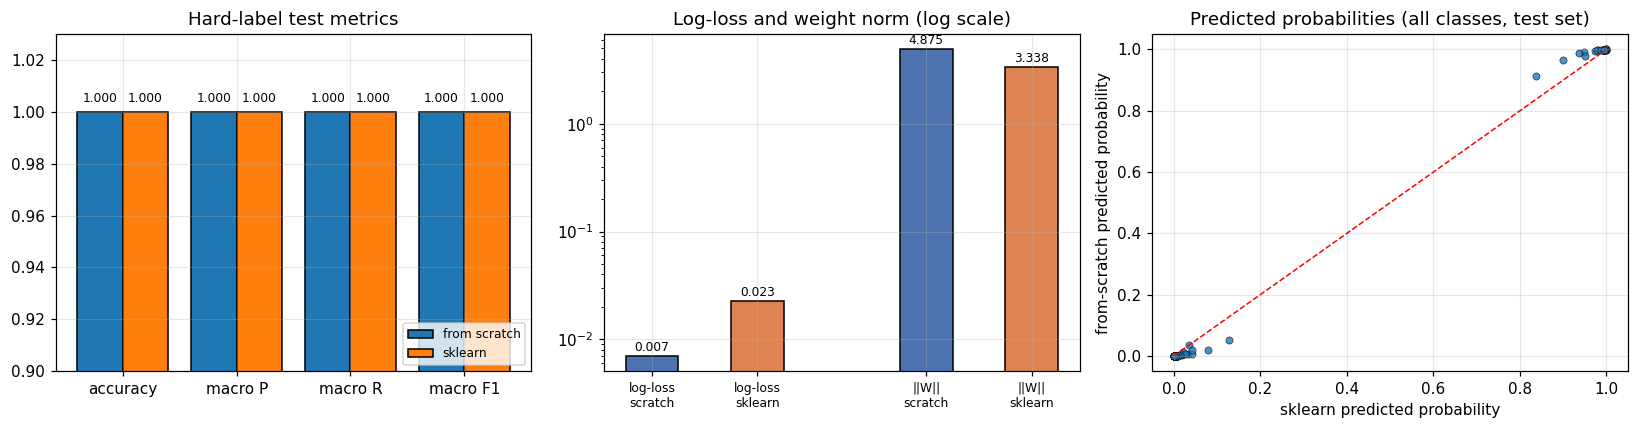

In [8]:
# =============================================================================
# CELL 8 : Q1(c) - COMPARISON WITH sklearn.linear_model.LogisticRegression
# =============================================================================
# The library model is fitted on exactly the same standardised training data.
# Defaults: L2 penalty with C = 1.0 and the lbfgs solver, i.e. a REGULARISED
# multinomial model optimised by a quasi-Newton method - two differences from
# our unregularised, first-order, fixed-step implementation.
# =============================================================================

sk_model = LogisticRegression(max_iter=5000)          # library defaults
sk_model.fit(Xtr, ytr)                                # bias handled internally

P_test_sk = sk_model.predict_proba(Xte)
yhat_sk = sk_model.predict(Xte)

cm_sk = confusion_matrix_scratch(yte, yhat_sk, K_WINE)
prec_k, rec_k, f1_k = prf_from_confusion(cm_sk)
acc_sk = accuracy(yte, yhat_sk)
ll_sk = log_loss_scratch(yte, P_test_sk)              # our own log-loss function

print("=" * 78)
print("sklearn LogisticRegression - TEST SET RESULTS")
print("=" * 78)
print("Solver : {} | penalty : {} | C : {} | iterations used : {}"
      .format(sk_model.solver, sk_model.penalty, sk_model.C, sk_model.n_iter_))
print()
print("Confusion matrix")
print(pd.DataFrame(cm_sk,
                   index=["true_" + c for c in class_names],
                   columns=["pred_" + c for c in class_names]).to_string())
print()
print("accuracy        : {:.4f}".format(acc_sk))
print("macro precision : {:.4f}".format(macro_average(prec_k)))
print("macro recall    : {:.4f}".format(macro_average(rec_k)))
print("macro F1        : {:.4f}".format(macro_average(f1_k)))
print("log-loss        : {:.6f}".format(ll_sk))

# --- side-by-side comparison table ---------------------------------------------
compare = pd.DataFrame({
    "metric": ["accuracy", "macro precision", "macro recall", "macro F1", "log-loss"],
    "from_scratch_softmax": [acc_scratch, macro_average(prec_s), macro_average(rec_s),
                             macro_average(f1_s), ll_scratch],
    "sklearn_LogisticRegression": [acc_sk, macro_average(prec_k), macro_average(rec_k),
                                   macro_average(f1_k), ll_sk],
})
print()
print("=" * 78)
print("SIDE BY SIDE COMPARISON ON THE TEST SET")
print("=" * 78)
print(compare.round(6).to_string(index=False))

# --- how similar are the two decision functions ? ------------------------------
agree = float(np.mean(yhat_scratch == yhat_sk))
max_prob_gap = float(np.abs(P_test_scratch - P_test_sk).max())
norm_scratch = float(np.linalg.norm(theta_best[1:]))    # exclude the bias row
norm_sk = float(np.linalg.norm(sk_model.coef_))
print()
print("agreement between the two models on the test set : {:.4f}".format(agree))
print("largest absolute difference in predicted probability : {:.4f}".format(max_prob_gap))
print("||W|| from scratch (unregularised) : {:.3f}".format(norm_scratch))
print("||W|| sklearn (L2, C = 1)          : {:.3f}".format(norm_sk))
print()
print("The from-scratch weights are the larger ones because nothing stops them")
print("from growing on this linearly separable dataset, whereas the L2 penalty")
print("of the library model keeps its coefficients small; that shrinkage is")
print("precisely what makes the two log-loss values differ.")

# --- figure : where the two models agree and where they differ ----------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

bar_x = np.arange(4)
b1 = ax[0].bar(bar_x - 0.2, compare["from_scratch_softmax"][:4], 0.4,
               label="from scratch", edgecolor="k")
b2 = ax[0].bar(bar_x + 0.2, compare["sklearn_LogisticRegression"][:4], 0.4,
               label="sklearn", edgecolor="k")
for b in list(b1) + list(b2):
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.004,
               "{:.3f}".format(b.get_height()), ha="center", fontsize=8)
ax[0].set_xticks(bar_x)
ax[0].set_xticklabels(["accuracy", "macro P", "macro R", "macro F1"])
ax[0].set_ylim(0.90, 1.03)
ax[0].set_title("Hard-label test metrics")
ax[0].legend(loc="lower right", fontsize=8)

# the metrics above are identical, so the interesting comparison is the one
# below : confidence (log-loss) and the size of the learned weights
b3 = ax[1].bar([0, 1], [ll_scratch, ll_sk], 0.5, color=["#4C72B0", "#DD8452"],
               edgecolor="k")
ax[1].bar([2.6, 3.6], [norm_scratch, norm_sk], 0.5, color=["#4C72B0", "#DD8452"],
          edgecolor="k")
ax[1].set_xticks([0, 1, 2.6, 3.6])
ax[1].set_xticklabels(["log-loss\nscratch", "log-loss\nsklearn",
                       "||W||\nscratch", "||W||\nsklearn"], fontsize=8)
ax[1].set_yscale("log")
for x, v in zip([0, 1, 2.6, 3.6], [ll_scratch, ll_sk, norm_scratch, norm_sk]):
    ax[1].text(x, v * 1.12, "{:.3f}".format(v), ha="center", fontsize=8)
ax[1].set_title("Log-loss and weight norm (log scale)")

ax[2].scatter(P_test_sk.ravel(), P_test_scratch.ravel(), s=22,
              edgecolors="k", linewidths=0.4, alpha=0.8)
ax[2].plot([0, 1], [0, 1], "r--", lw=1)
ax[2].set_xlabel("sklearn predicted probability")
ax[2].set_ylabel("from-scratch predicted probability")
ax[2].set_title("Predicted probabilities (all classes, test set)")

plt.tight_layout()
plt.savefig(f"{FIGDIR}/q1c_scratch_vs_sklearn.png", bbox_inches="tight")
plt.show()


In [9]:
# =============================================================================
# CELL 9 : Q2 - HELPER THAT DRAWS AN SVM BOUNDARY, ITS MARGINS AND ITS SVs
# =============================================================================

def plot_linear_svm(ax, model, X, y, title):
    """
    Draw, on the axes `ax`:
      - the data, coloured by class;
      - the decision boundary   w.x + b =  0  (solid line);
      - the two margin boundaries w.x + b = +-1 (dashed lines);
      - a ring around every support vector.

    All three lines are contours of model.decision_function at levels -1, 0, +1,
    so they are obtained directly from the fitted model rather than redrawn by
    hand. The geometric margin of a linear SVM is 1/||w|| on each side, hence a
    total margin width of 2/||w||, which is printed in the panel title.
    """
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=30,
               edgecolors="k", linewidths=0.5, zorder=3)

    # rectangular grid covering the data, used to evaluate the decision function
    pad = 0.8
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                         np.linspace(y_min, y_max, 400))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[1.0, 1.8, 1.0])
    ax.contourf(xx, yy, Z, levels=[Z.min(), 0, Z.max()],
                colors=["#4C72B0", "#C44E52"], alpha=0.10)

    # support vectors : the only training points that define the solution
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=170, facecolors="none",
               edgecolors="#00A000", linewidths=1.7, zorder=4,
               label="support vectors ({})".format(len(sv)))

    margin = 2.0 / np.linalg.norm(model.coef_)
    ax.set_title("{}\nmargin width 2/||w|| = {:.3f}".format(title, margin), fontsize=10)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    ax.legend(loc="best", fontsize=8)
    return margin


print("SVM plotting helper defined.")


SVM plotting helper defined.


Q2(a) - LINEARLY SEPARABLE BLOBS (cluster_std = 0.60, seed = 42)
samples                      : 60
weight vector w              : [ 0.1861 -0.1834]
bias b                       : 0.8813
||w||                        : 0.2613
margin width 2/||w||         : 7.6540
number of support vectors    : 2 (per class: [1 1] )
training accuracy            : 1.0000

Support vector coordinates :
[[-2.3839  7.8385]
 [ 3.068   2.4663]]

Functional margin |w.x + b| at each support vector (should all be 1) :
[1. 1.]


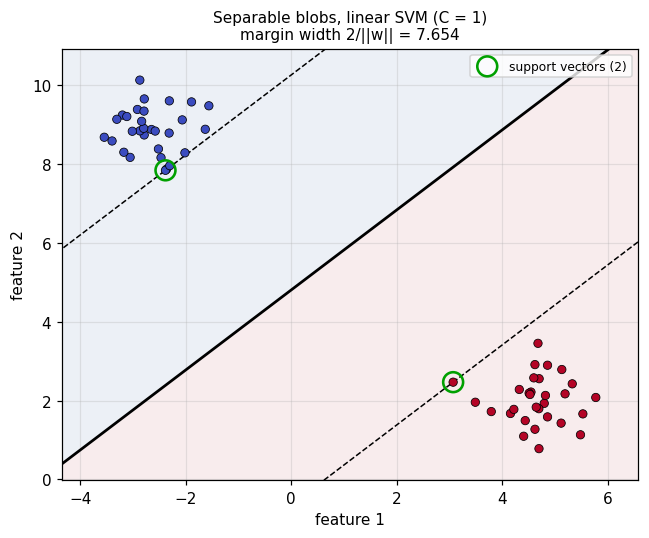

In [10]:
# =============================================================================
# CELL 10 : Q2(a) - GEOMETRIC INTUITION ON WELL SEPARATED SYNTHETIC 2D DATA
# =============================================================================

X_sep, y_sep = make_blobs(n_samples=60, centers=2, n_features=2,
                          cluster_std=0.60, random_state=RANDOM_SEED)

svm_sep = SVC(kernel="linear", C=1.0)
svm_sep.fit(X_sep, y_sep)

print("=" * 78)
print("Q2(a) - LINEARLY SEPARABLE BLOBS (cluster_std = 0.60, seed = 42)")
print("=" * 78)
print("samples                      :", X_sep.shape[0])
print("weight vector w              :", svm_sep.coef_[0])
print("bias b                       : {:.4f}".format(svm_sep.intercept_[0]))
print("||w||                        : {:.4f}".format(np.linalg.norm(svm_sep.coef_)))
print("margin width 2/||w||         : {:.4f}".format(2 / np.linalg.norm(svm_sep.coef_)))
print("number of support vectors    :", svm_sep.support_.size,
      "(per class:", svm_sep.n_support_, ")")
print("training accuracy            : {:.4f}".format(svm_sep.score(X_sep, y_sep)))
print()
print("Support vector coordinates :")
print(np.round(svm_sep.support_vectors_, 4))
print()
print("Functional margin |w.x + b| at each support vector (should all be 1) :")
print(np.round(np.abs(svm_sep.decision_function(svm_sep.support_vectors_)), 6))

fig, ax = plt.subplots(figsize=(6.0, 5.0))
MARGIN_SEP = plot_linear_svm(ax, svm_sep, X_sep, y_sep,
                             "Separable blobs, linear SVM (C = 1)")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q2a_separable.png", bbox_inches="tight")
plt.show()


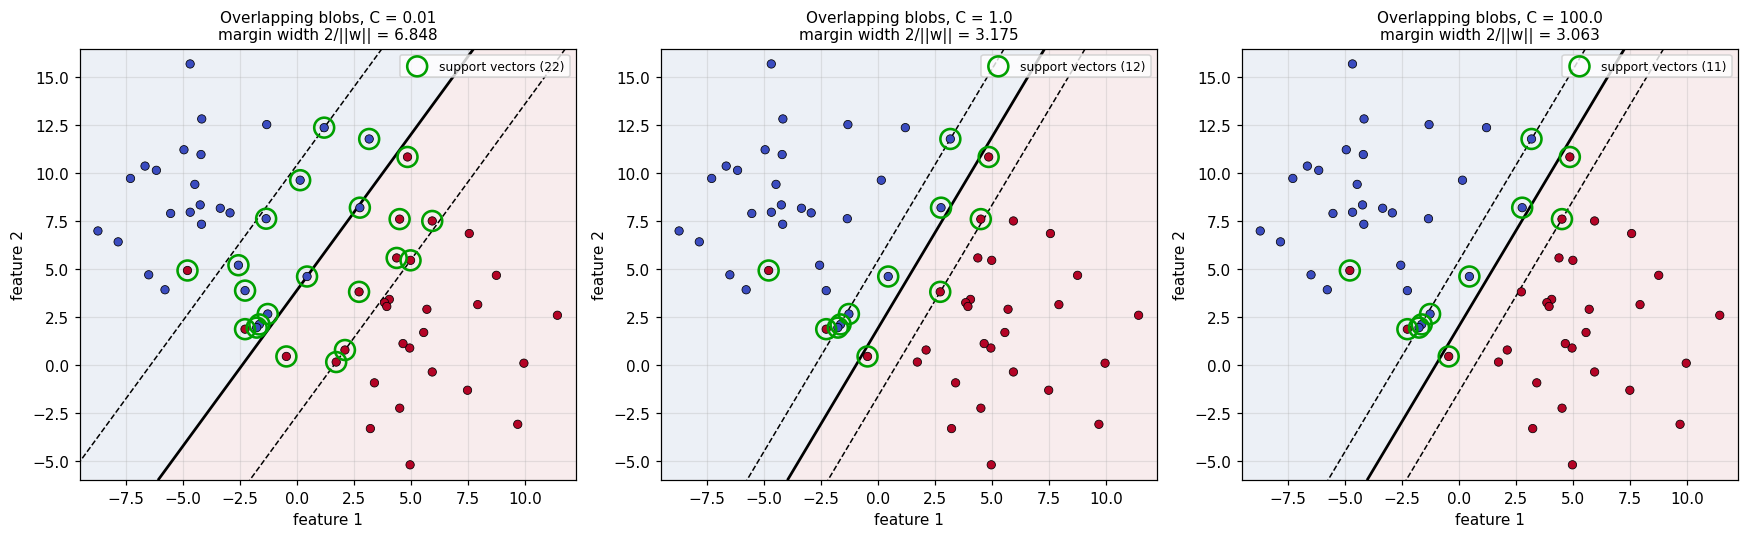

Q2(a) - EFFECT OF C ON THE OVERLAPPING BLOBS (cluster_std = 3.60)
     C  margin_width  norm_w  n_support_vectors  train_accuracy  train_misclassified
  0.01        6.8480  0.2921                 22          0.9333                    4
  1.00        3.1754  0.6298                 12          0.9667                    2
100.00        3.0626  0.6530                 11          0.9667                    2

Small C  -> the slack penalty is cheap, the optimiser buys a WIDE margin
            by tolerating violations; many points sit inside the margin
            and therefore many support vectors appear.
Large C  -> violations are expensive, the margin is squeezed until almost
            every training point is classified correctly and outside it;
            the boundary is pulled towards the few overlapping points.


In [11]:
# =============================================================================
# CELL 11 : Q2(a) - THE SAME BLOBS WITH CLASS OVERLAP, FOR THREE VALUES OF C
# =============================================================================
# Overlap is introduced by enlarging cluster_std; the seed stays at 42 so the
# only thing that changes between this experiment and the previous one is the
# spread of the two clusters.
# =============================================================================

X_ov, y_ov = make_blobs(n_samples=60, centers=2, n_features=2,
                        cluster_std=3.60, random_state=RANDOM_SEED)

C_VALUES_A = [0.01, 1.0, 100.0]
rows_a = []

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, C in zip(axes, C_VALUES_A):
    model = SVC(kernel="linear", C=C)
    model.fit(X_ov, y_ov)
    m = plot_linear_svm(ax, model, X_ov, y_ov, "Overlapping blobs, C = {}".format(C))
    n_err = int((model.predict(X_ov) != y_ov).sum())
    rows_a.append({
        "C": C,
        "margin_width": m,
        "norm_w": float(np.linalg.norm(model.coef_)),
        "n_support_vectors": int(model.support_.size),
        "train_accuracy": float(model.score(X_ov, y_ov)),
        "train_misclassified": n_err,
    })
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q2a_overlap_C.png", bbox_inches="tight")
plt.show()

tbl_a = pd.DataFrame(rows_a)
print("=" * 78)
print("Q2(a) - EFFECT OF C ON THE OVERLAPPING BLOBS (cluster_std = 3.60)")
print("=" * 78)
print(tbl_a.round(4).to_string(index=False))
print()
print("Small C  -> the slack penalty is cheap, the optimiser buys a WIDE margin")
print("            by tolerating violations; many points sit inside the margin")
print("            and therefore many support vectors appear.")
print("Large C  -> violations are expensive, the margin is squeezed until almost")
print("            every training point is classified correctly and outside it;")
print("            the boundary is pulled towards the few overlapping points.")


Q2(b) - OVERLAPPING make_classification DATASET (seed = 42)
total samples        : 250
training samples     : 200  (class 0 : 102, class 1 : 98)
validation samples   : 50  (class 0 : 25, class 1 : 25)


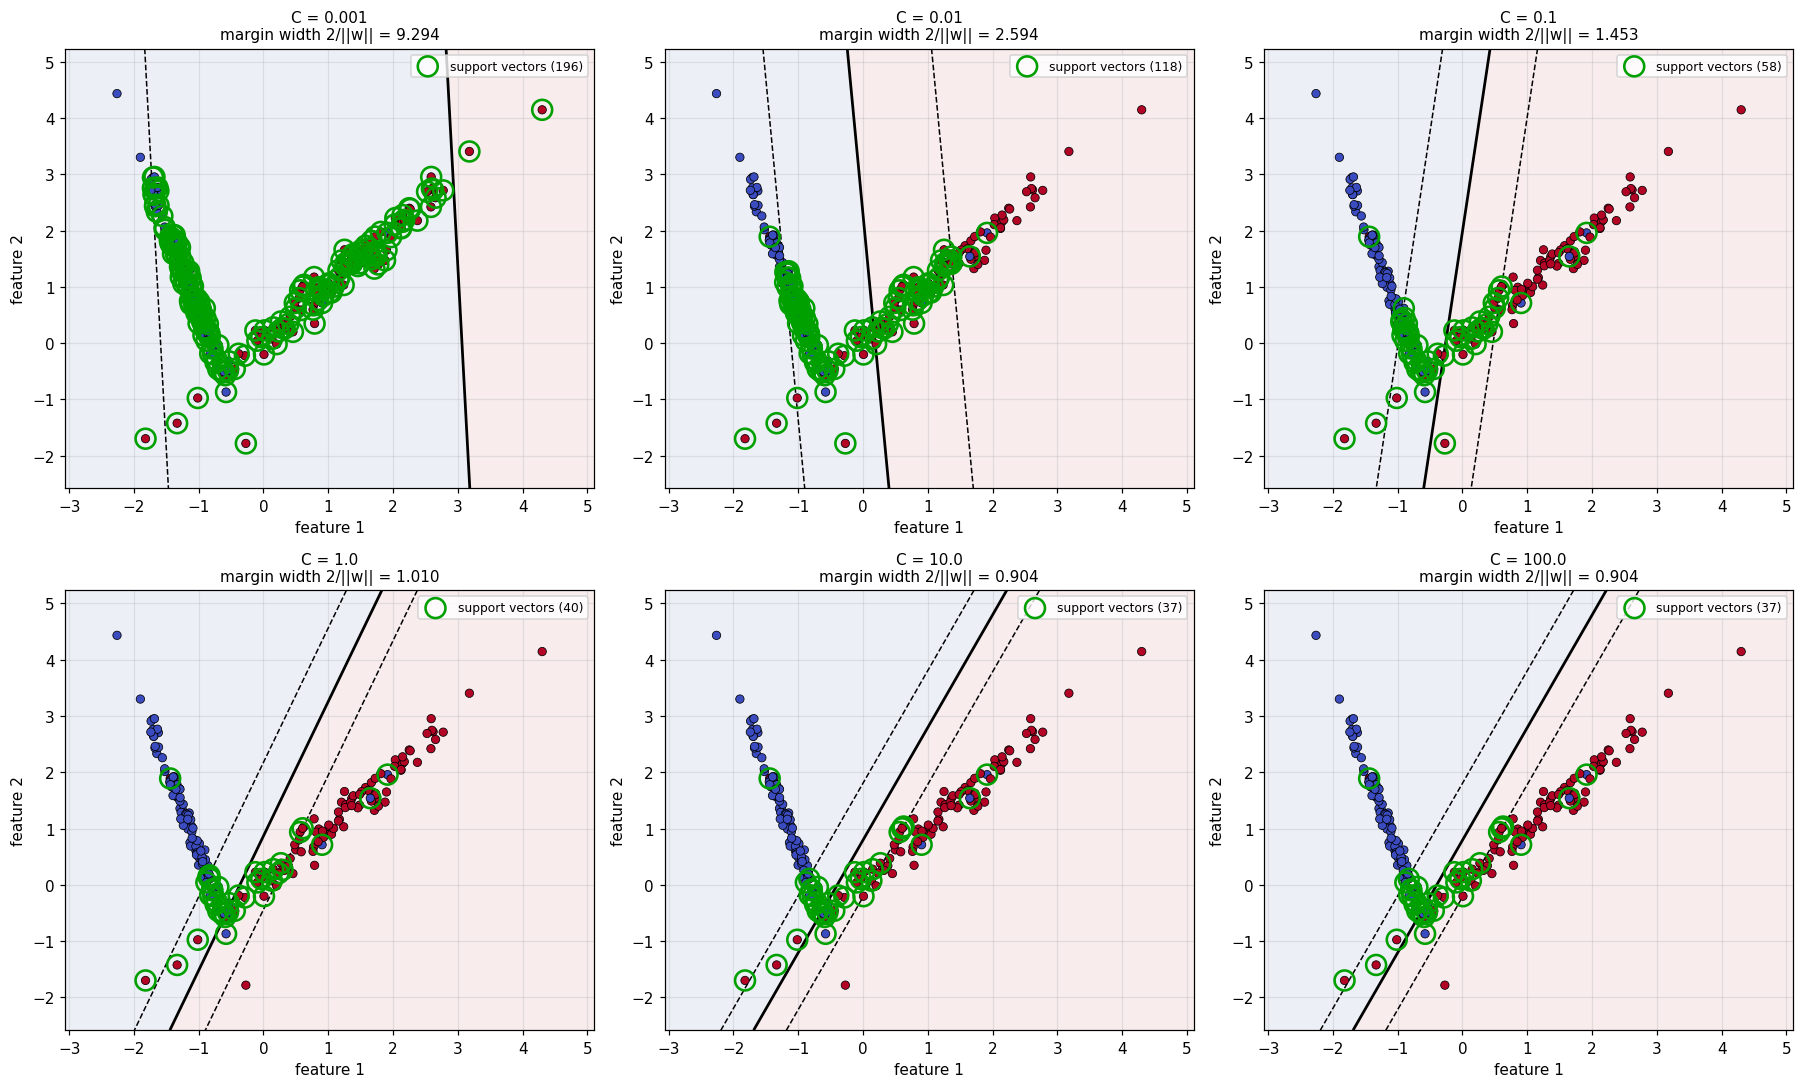


Q2(b) - TRAINING AND VALIDATION PERFORMANCE ACROSS C
      C  margin_width  norm_w  n_support_vectors  train_accuracy  val_accuracy
  0.001        9.2940  0.2152                196           0.520          0.50
  0.010        2.5936  0.7711                118           0.905          0.88
  0.100        1.4531  1.3764                 58           0.950          0.92
  1.000        1.0099  1.9804                 40           0.955          0.94
 10.000        0.9045  2.2112                 37           0.940          0.96
100.000        0.9044  2.2113                 37           0.940          0.96

Best C on the validation set : 10.0 (validation accuracy 0.9600)


In [12]:
# =============================================================================
# CELL 12 : Q2(b) - REGULARISATION SWEEP ON A NEW OVERLAPPING 2D DATASET
# =============================================================================

X_b, y_b = make_classification(n_samples=250, n_features=2, n_informative=2,
                               n_redundant=0, n_repeated=0, n_classes=2,
                               n_clusters_per_class=1, class_sep=1.20,
                               flip_y=0.08, random_state=RANDOM_SEED)
# class_sep = 1.2 with flip_y = 0.08 gives two clouds that clearly overlap and
# 8 % deliberately mislabelled points, so the classes are NOT separable.

# 80:20 split, stratified, same seed (the helper written in Cell 2 is reused
# with a two-way ratio, the validation block simply being empty).
idx_tr_b, _, idx_va_b = stratified_split(y_b, (0.80, 0.0, 0.20), seed=RANDOM_SEED)
Xb_tr, yb_tr = X_b[idx_tr_b], y_b[idx_tr_b]
Xb_va, yb_va = X_b[idx_va_b], y_b[idx_va_b]

print("=" * 78)
print("Q2(b) - OVERLAPPING make_classification DATASET (seed = 42)")
print("=" * 78)
print("total samples        :", X_b.shape[0])
print("training samples     : {}  (class 0 : {}, class 1 : {})"
      .format(yb_tr.size, int((yb_tr == 0).sum()), int((yb_tr == 1).sum())))
print("validation samples   : {}  (class 0 : {}, class 1 : {})"
      .format(yb_va.size, int((yb_va == 0).sum()), int((yb_va == 1).sum())))

C_VALUES_B = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]     # six orders of magnitude
rows_b = []

fig, axes = plt.subplots(2, 3, figsize=(16.5, 10))
for ax, C in zip(axes.ravel(), C_VALUES_B):
    model = SVC(kernel="linear", C=C)
    model.fit(Xb_tr, yb_tr)
    m = plot_linear_svm(ax, model, Xb_tr, yb_tr, "C = {}".format(C))
    rows_b.append({
        "C": C,
        "margin_width": m,
        "norm_w": float(np.linalg.norm(model.coef_)),
        "n_support_vectors": int(model.support_.size),
        "train_accuracy": float(model.score(Xb_tr, yb_tr)),
        "val_accuracy": float(model.score(Xb_va, yb_va)),
    })
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q2b_boundaries.png", bbox_inches="tight")
plt.show()

tbl_b = pd.DataFrame(rows_b)
print()
print("=" * 78)
print("Q2(b) - TRAINING AND VALIDATION PERFORMANCE ACROSS C")
print("=" * 78)
print(tbl_b.round(4).to_string(index=False))

# highest validation accuracy; ties broken towards the SMALLER C, i.e. towards
# the wider margin and the more regularised model
best_val_b = tbl_b["val_accuracy"].max()
best_C_b = float(tbl_b.loc[tbl_b["val_accuracy"] == best_val_b, "C"].min())
print()
print("Best C on the validation set : {} (validation accuracy {:.4f})"
      .format(best_C_b, best_val_b))


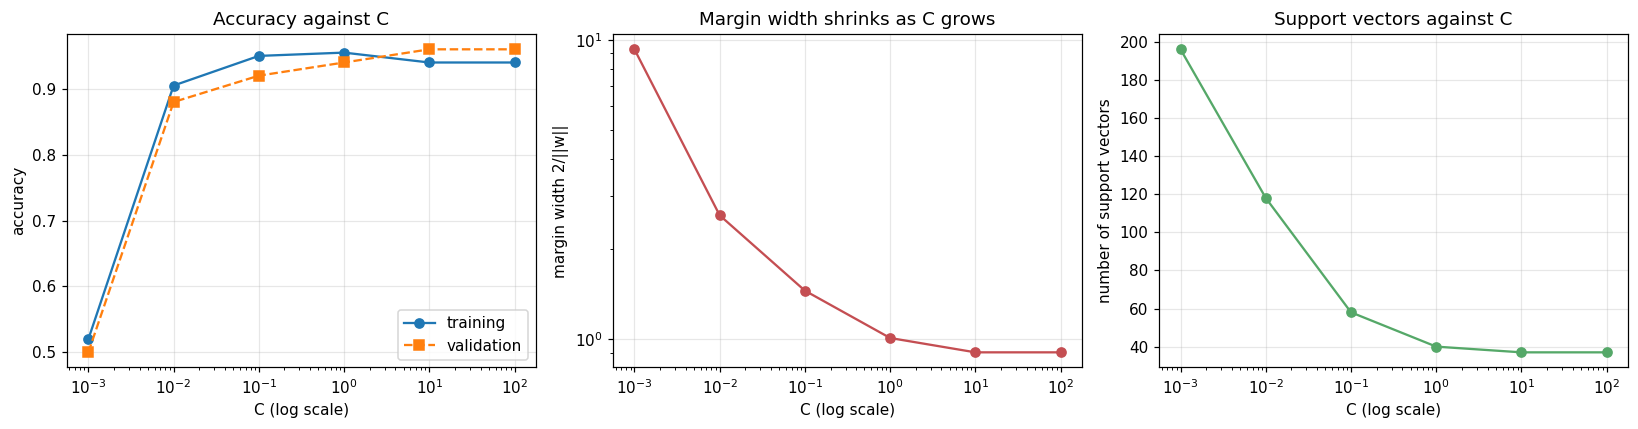

As C increases the margin narrows and the number of support vectors falls,
because fewer points are permitted to sit inside the margin. At the very
small end of the range the penalty on slack is so weak that the model
underfits badly; accuracy then improves sharply and finally plateaus, the
boundary hardly moving once C is large enough for the hinge loss to
dominate the 1/2||w||^2 term.


In [13]:
# =============================================================================
# CELL 13 : Q2(b) - SUMMARY CURVES OF THE REGULARISATION SWEEP
# =============================================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].semilogx(tbl_b["C"], tbl_b["train_accuracy"], "o-", label="training")
ax[0].semilogx(tbl_b["C"], tbl_b["val_accuracy"], "s--", label="validation")
ax[0].set_xlabel("C (log scale)")
ax[0].set_ylabel("accuracy")
ax[0].set_title("Accuracy against C")
ax[0].legend()

ax[1].loglog(tbl_b["C"], tbl_b["margin_width"], "o-", color="#C44E52")
ax[1].set_xlabel("C (log scale)")
ax[1].set_ylabel("margin width 2/||w||")
ax[1].set_title("Margin width shrinks as C grows")

ax[2].semilogx(tbl_b["C"], tbl_b["n_support_vectors"], "o-", color="#55A868")
ax[2].set_xlabel("C (log scale)")
ax[2].set_ylabel("number of support vectors")
ax[2].set_title("Support vectors against C")

plt.tight_layout()
plt.savefig(f"{FIGDIR}/q2b_curves.png", bbox_inches="tight")
plt.show()

print("As C increases the margin narrows and the number of support vectors falls,")
print("because fewer points are permitted to sit inside the margin. At the very")
print("small end of the range the penalty on slack is so weak that the model")
print("underfits badly; accuracy then improves sharply and finally plateaus, the")
print("boundary hardly moving once C is large enough for the hinge loss to")
print("dominate the 1/2||w||^2 term.")


In [14]:
# =============================================================================
# CELL 14 : Q2(c) - BREAST CANCER WISCONSIN : LOAD, SPLIT 70:15:15, STANDARDISE
# =============================================================================

bc = load_breast_cancer()
X_bc, y_bc = bc.data, bc.target                 # 569 x 30, labels 0 = malignant, 1 = benign
bc_classes = [str(c) for c in bc.target_names]

print("=" * 78)
print("BREAST CANCER WISCONSIN DATASET")
print("=" * 78)
print("shape       :", X_bc.shape)
print("classes     :", bc_classes, "-> 0 =", bc_classes[0], ", 1 =", bc_classes[1])
cnt_bc = np.bincount(y_bc)
print("class counts: {} = {}, {} = {}  (proportion {:.3f} / {:.3f})"
      .format(bc_classes[0], cnt_bc[0], bc_classes[1], cnt_bc[1],
              cnt_bc[0] / y_bc.size, cnt_bc[1] / y_bc.size))

# --- stratified 70:15:15 split with seed 42 -----------------------------------
tr_c, va_c, te_c = stratified_split(y_bc, (0.70, 0.15, 0.15), seed=RANDOM_SEED)
Xc_tr_raw, yc_tr = X_bc[tr_c], y_bc[tr_c]
Xc_va_raw, yc_va = X_bc[va_c], y_bc[va_c]
Xc_te_raw, yc_te = X_bc[te_c], y_bc[te_c]

split_c = pd.DataFrame({
    "subset": ["train", "validation", "test"],
    "n_samples": [yc_tr.size, yc_va.size, yc_te.size],
    "malignant": [int((yc_tr == 0).sum()), int((yc_va == 0).sum()), int((yc_te == 0).sum())],
    "benign": [int((yc_tr == 1).sum()), int((yc_va == 1).sum()), int((yc_te == 1).sum())],
})
print()
print(split_c.to_string(index=False))

# --- standardise with training statistics only --------------------------------
Xc_tr, Xc_va, Xc_te, (mu_c, sd_c) = standardize(Xc_tr_raw, Xc_va_raw, Xc_te_raw)
print()
print("standardisation done with training mean/std only")
print("training mean (first 4 features) :", np.round(Xc_tr.mean(axis=0)[:4], 6))
print("training std  (first 4 features) :", np.round(Xc_tr.std(axis=0)[:4], 6))
print("test mean     (first 4 features) :", np.round(Xc_te.mean(axis=0)[:4], 4))


BREAST CANCER WISCONSIN DATASET
shape       : (569, 30)
classes     : ['malignant', 'benign'] -> 0 = malignant , 1 = benign
class counts: malignant = 212, benign = 357  (proportion 0.373 / 0.627)

    subset  n_samples  malignant  benign
     train        398        148     250
validation         86         32      54
      test         85         32      53

standardisation done with training mean/std only
training mean (first 4 features) : [-0. -0.  0.  0.]
training std  (first 4 features) : [1. 1. 1. 1.]
test mean     (first 4 features) : [-0.0383 -0.013  -0.0436 -0.0517]


Q2(c) - MODEL SELECTION SWEEP OVER C
      C  n_support_vectors  margin_width  train_accuracy  val_accuracy  val_roc_auc  test_accuracy
  0.001                195        6.3650          0.9447        0.9535       0.9988         0.8824
  0.010                 90        2.9913          0.9698        0.9884       0.9988         0.9647
  0.100                 46        1.5266          0.9849        0.9884       1.0000         0.9529
  1.000                 31        0.6956          0.9925        1.0000       1.0000         0.9529
 10.000                 27        0.2656          0.9950        0.9651       1.0000         0.9412
100.000                 22        0.0927          1.0000        0.9651       1.0000         0.9412

SELECTED C                      : 1.0
validation accuracy at this C   : 1.0000
number of support vectors       : 31  (per class : [14 17])
that is 7.8 % of the 398 training samples
margin width 2/||w||            : 0.6956


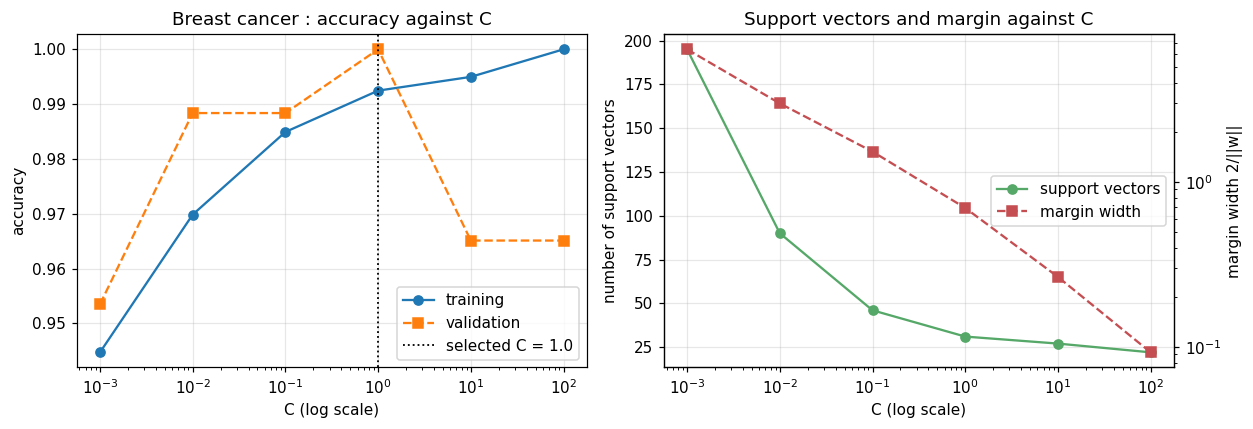

In [15]:
# =============================================================================
# CELL 15 : Q2(c) - SELECTING C ON THE VALIDATION SET
# =============================================================================

C_VALUES_C = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
rows_c = []
models_c = {}

for C in C_VALUES_C:
    model = SVC(kernel="linear", C=C)
    model.fit(Xc_tr, yc_tr)
    models_c[C] = model
    rows_c.append({
        "C": C,
        "n_support_vectors": int(model.support_.size),
        "margin_width": float(2.0 / np.linalg.norm(model.coef_)),
        "train_accuracy": float(model.score(Xc_tr, yc_tr)),
        "val_accuracy": float(model.score(Xc_va, yc_va)),
        "val_roc_auc": float(roc_auc_score(yc_va, model.decision_function(Xc_va))),
        "test_accuracy": float(model.score(Xc_te, yc_te)),
    })

tbl_c = pd.DataFrame(rows_c)
print("=" * 78)
print("Q2(c) - MODEL SELECTION SWEEP OVER C")
print("=" * 78)
print(tbl_c.round(4).to_string(index=False))

# --- selection rule : highest validation accuracy, ties broken by the SMALLER C
# (the smaller C gives the wider margin, i.e. the simpler and more regularised
#  model, which is the standard tie-breaking convention).
best_val = tbl_c["val_accuracy"].max()
best_C_c = float(tbl_c.loc[tbl_c["val_accuracy"] == best_val, "C"].min())
best_model_c = models_c[best_C_c]

print()
print("SELECTED C                      : {}".format(best_C_c))
print("validation accuracy at this C   : {:.4f}".format(best_val))
print("number of support vectors       : {}  (per class : {})"
      .format(best_model_c.support_.size, best_model_c.n_support_))
print("that is {:.1f} % of the {} training samples"
      .format(100 * best_model_c.support_.size / yc_tr.size, yc_tr.size))
print("margin width 2/||w||            : {:.4f}"
      .format(2.0 / np.linalg.norm(best_model_c.coef_)))

# --- figure : validation behaviour against C ----------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].semilogx(tbl_c["C"], tbl_c["train_accuracy"], "o-", label="training")
ax[0].semilogx(tbl_c["C"], tbl_c["val_accuracy"], "s--", label="validation")
ax[0].axvline(best_C_c, color="k", ls=":", lw=1.2, label="selected C = {}".format(best_C_c))
ax[0].set_xlabel("C (log scale)")
ax[0].set_ylabel("accuracy")
ax[0].set_title("Breast cancer : accuracy against C")
ax[0].legend()

ax[1].semilogx(tbl_c["C"], tbl_c["n_support_vectors"], "o-", color="#55A868",
               label="support vectors")
ax[1].set_xlabel("C (log scale)")
ax[1].set_ylabel("number of support vectors")
ax2 = ax[1].twinx()
ax2.semilogx(tbl_c["C"], tbl_c["margin_width"], "s--", color="#C44E52",
             label="margin width")
ax2.set_ylabel("margin width 2/||w||")
ax2.set_yscale("log")
ax2.grid(False)
ax[1].set_title("Support vectors and margin against C")
lines = ax[1].get_lines() + ax2.get_lines()
ax[1].legend(lines, [l.get_label() for l in lines], loc="center right")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/q2c_C_selection.png", bbox_inches="tight")
plt.show()


Q2(c) - TEST SET RESULTS FOR THE SELECTED LINEAR SVM (C = 1.0)
Confusion matrix (rows = true, columns = predicted)
                pred_malignant  pred_benign
true_malignant              28            4
true_benign                  0           53

accuracy                       : 0.9529
precision (positive = benign)  : 0.9298
recall    (positive = benign)  : 1.0000
F1        (positive = benign)  : 0.9636
ROC-AUC   (decision function)  : 0.9982

per class :
    class  support  precision  recall     f1
malignant       32     1.0000   0.875 0.9333
   benign       53     0.9298   1.000 0.9636

macro F1 : 0.9485

TEST METRICS FOR EVERY C CONSIDERED (positive class = benign)
      C  n_SV  accuracy  precision  recall     f1  roc_auc
  0.001   195    0.8824     0.8413     1.0 0.9138   0.9917
  0.010    90    0.9647     0.9464     1.0 0.9725   0.9953
  0.100    46    0.9529     0.9298     1.0 0.9636   0.9982
  1.000    31    0.9529     0.9298     1.0 0.9636   0.9982
 10.000    27    0.9412    

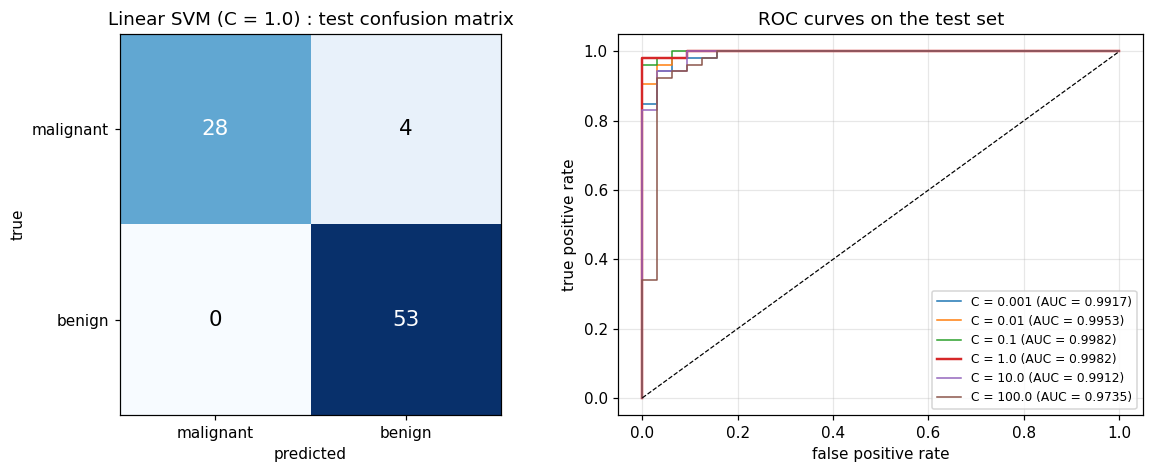

In [16]:
# =============================================================================
# CELL 16 : Q2(c) - FINAL TEST-SET EVALUATION OF THE SELECTED LINEAR SVM
# =============================================================================
# The positive class is "benign" (label 1), which is what sklearn's decision
# function scores as positive; precision, recall and F1 are reported for it, and
# the ROC-AUC is computed from the raw decision-function values, NOT from hard
# labels, exactly as the problem sheet asks.
# =============================================================================

scores_te = best_model_c.decision_function(Xc_te)     # signed distance x ||w||
yhat_te = best_model_c.predict(Xc_te)

cm_c = confusion_matrix_scratch(yc_te, yhat_te, 2)
prec_c, rec_c, f1_c = prf_from_confusion(cm_c)
acc_c = accuracy(yc_te, yhat_te)
auc_c = roc_auc_score(yc_te, scores_te)

print("=" * 78)
print("Q2(c) - TEST SET RESULTS FOR THE SELECTED LINEAR SVM (C = {})".format(best_C_c))
print("=" * 78)
print("Confusion matrix (rows = true, columns = predicted)")
print(pd.DataFrame(cm_c,
                   index=["true_malignant", "true_benign"],
                   columns=["pred_malignant", "pred_benign"]).to_string())
print()
print("accuracy                       : {:.4f}".format(acc_c))
print("precision (positive = benign)  : {:.4f}".format(prec_c[1]))
print("recall    (positive = benign)  : {:.4f}".format(rec_c[1]))
print("F1        (positive = benign)  : {:.4f}".format(f1_c[1]))
print("ROC-AUC   (decision function)  : {:.4f}".format(auc_c))
print()
print("per class :")
print(pd.DataFrame({
    "class": ["malignant", "benign"],
    "support": cm_c.sum(axis=1),
    "precision": prec_c,
    "recall": rec_c,
    "f1": f1_c,
}).round(4).to_string(index=False))
print()
print("macro F1 : {:.4f}".format(macro_average(f1_c)))

# --- test metrics for every C, for the comparison asked for -------------------
rows_test = []
for C in C_VALUES_C:
    mdl = models_c[C]
    sc = mdl.decision_function(Xc_te)
    yh = mdl.predict(Xc_te)
    cmx = confusion_matrix_scratch(yc_te, yh, 2)
    p, r, f = prf_from_confusion(cmx)
    rows_test.append({
        "C": C,
        "n_SV": int(mdl.support_.size),
        "accuracy": accuracy(yc_te, yh),
        "precision": p[1],
        "recall": r[1],
        "f1": f[1],
        "roc_auc": float(roc_auc_score(yc_te, sc)),
    })
tbl_test_c = pd.DataFrame(rows_test)
print()
print("=" * 78)
print("TEST METRICS FOR EVERY C CONSIDERED (positive class = benign)")
print("=" * 78)
print(tbl_test_c.round(4).to_string(index=False))

# --- figure : confusion matrix and ROC curve ----------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))

im = ax[0].imshow(cm_c, cmap="Blues")
ax[0].set_xticks([0, 1])
ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(["malignant", "benign"])
ax[0].set_yticklabels(["malignant", "benign"])
ax[0].set_xlabel("predicted")
ax[0].set_ylabel("true")
ax[0].set_title("Linear SVM (C = {}) : test confusion matrix".format(best_C_c))
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm_c[i, j], ha="center", va="center", fontsize=14,
                   color="white" if cm_c[i, j] > cm_c.max() / 2 else "black")
ax[0].grid(False)

for C in C_VALUES_C:
    fpr, tpr, _ = roc_curve(yc_te, models_c[C].decision_function(Xc_te))
    a = roc_auc_score(yc_te, models_c[C].decision_function(Xc_te))
    ax[1].plot(fpr, tpr, lw=1.6 if C == best_C_c else 1.0,
               label="C = {} (AUC = {:.4f})".format(C, a))
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_xlabel("false positive rate")
ax[1].set_ylabel("true positive rate")
ax[1].set_title("ROC curves on the test set")
ax[1].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/q2c_test_results.png", bbox_inches="tight")
plt.show()


In [17]:
# =============================================================================
# CELL 17 : CONSOLIDATED SUMMARY OF EVERY HEADLINE RESULT
# =============================================================================

print("=" * 78)
print("LAB 4 - SUMMARY OF RESULTS")
print("=" * 78)
print("Q1  Wine, softmax regression from scratch")
print("     selected learning rate            : {}".format(best_lr))
print("     test accuracy (from scratch)      : {:.4f}".format(acc_scratch))
print("     test macro F1 (from scratch)      : {:.4f}".format(macro_average(f1_s)))
print("     test log-loss (from scratch)      : {:.4f}".format(ll_scratch))
print("     test accuracy (sklearn)           : {:.4f}".format(acc_sk))
print("     test log-loss (sklearn)           : {:.4f}".format(ll_sk))
print("     K = 2 reduction, max |theta - w|  : {:.2e}".format(VERIF_MAX_THETA))
print()
print("Q2  Support vector machines")
print("     separable blobs, margin width     : {:.4f}".format(MARGIN_SEP))
print("     separable blobs, support vectors  : {}".format(svm_sep.support_.size))
print("     synthetic sweep, best C           : {}".format(best_C_b))
print("     breast cancer, selected C         : {}".format(best_C_c))
print("     breast cancer, support vectors    : {}".format(best_model_c.support_.size))
print("     breast cancer, test accuracy      : {:.4f}".format(acc_c))
print("     breast cancer, test F1            : {:.4f}".format(f1_c[1]))
print("     breast cancer, test ROC-AUC       : {:.4f}".format(auc_c))
print("=" * 78)


LAB 4 - SUMMARY OF RESULTS
Q1  Wine, softmax regression from scratch
     selected learning rate            : 0.05
     test accuracy (from scratch)      : 1.0000
     test macro F1 (from scratch)      : 1.0000
     test log-loss (from scratch)      : 0.0070
     test accuracy (sklearn)           : 1.0000
     test log-loss (sklearn)           : 0.0228
     K = 2 reduction, max |theta - w|  : 4.44e-16

Q2  Support vector machines
     separable blobs, margin width     : 7.6540
     separable blobs, support vectors  : 2
     synthetic sweep, best C           : 10.0
     breast cancer, selected C         : 1.0
     breast cancer, support vectors    : 31
     breast cancer, test accuracy      : 0.9529
     breast cancer, test F1            : 0.9636
     breast cancer, test ROC-AUC       : 0.9982
